# Water–fat chemical-shift MRI: active reconstruction and review

## 1. Problem

Reconstruct separate three-dimensional water and fat signal images, fat signal fraction, off-resonance field and transverse decay rate from three complex MRI echoes despite chemical-shift ambiguity and field inhomogeneity.

We actively reconstruct every voxel of the author-supplied challenge case17 three-echo volume with cleaned local mathematics. A captured author run is an identified standard-method comparison, **not anatomical truth**. Full2015 ISMRM3653 was read;2017 journal abstract is context and access to its full text was unavailable. This current author-code variant retains complex coefficients, six fat peaks, coarse-to-fine QPBO and the source conditional updates.

The self-contained public README specifies the physical signal, acquisition and output. This notebook explains the inverse process, checks independently captured author stages through tests, evaluates all five fresh outputs and examines the scientific limits. Source artifacts and historical13-case reports are not substituted for these computations.


## 2. Data

`data/raw_data.npz` contains only the observed complex echo images. No separate target image, fitted field or target-derived calibration is available as input.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| echoes | (1, 3, 101, 101, 4) | complex64 | Complex MRI signal in arbitrary signal units; axes batch,echo,x,y,z; stored real and imaginary parts jointly retain the acquisition phase convention. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Source example | Challenge case17, author-distributed observation volume | dimensionless | Full volume; anatomical orientation and subject details were not supplied in the example. |
| Echo times | 0.00287,0.00607,0.00927 | s | Three equally spaced complex echoes. |
| Echo spacing | 0.0032 | s | Difference between consecutive echo times. |
| Main magnetic field | 1.494 | T | Nominal field for chemical-shift conversion. |
| Proton gyromagnetic ratio | 42.576 | MHz/T | Multiplied by ppm chemical shifts to obtain Hz. |
| Voxel spacing | 1.5,1.5,5.0 | mm | Spacing along stored x,y,z axes. |
| Temperature convention | 37 | degrees Celsius | Known author-example model calibration; water shift follows1.3+3.748−0.01085 times temperature. |
| Water chemical shift | 4.64655 | ppm | Computed using the stated temperature convention, represented in float32 before spectral modeling. |
| Fat chemical shifts | 5.3,4.31,2.76,2.1,1.3,0.9 | ppm | Six fat resonances, represented in float32. |
| Fat relative weights | 0.048,0.039,0.004,0.128,0.693,0.087 | dimensionless | Retain original float32 weights and their supplied sum rather than renormalizing. |
| Precession convention | Positive complex exponential | dimensionless | Echo data are not conjugated before reconstruction. |
| Spatial boundary convention | Nonperiodic in x,y,z | dimensionless | Spatial neighbors do not wrap across volume edges. |
| Coil combination and intensity calibration | Not supplied | dimensionless | Absolute spin density cannot be inferred. |
| Noise covariance | Not supplied | squared signal unit | Use unweighted complex residuals; do not infer a hidden noise map. |


## 3. Physics

The observations are the complete author-supplied case17 demonstration volume from a fat–water reconstruction challenge. They contain three complex echoes and four adjacent spatial slices. No anatomical orientation, subject diagnosis or additional calibration scan is supplied. Reconstruct all five quantities below on the entire supplied grid.

Let the complex observation at spatial voxel position $\mathbf r$ and echo index $n=0,1,2$ be $s_n(\mathbf r)$. A first-echo-referenced signal model is


$$
s_n(\mathbf r)=e^{i2\pi f(\mathbf r)n\Delta t}
e^{-R(\mathbf r)(t_n-t_0)}
\left[W(\mathbf r)+C(\mathbf r)
\sum_{p=1}^{6}a_p e^{i2\pi\gamma B_0(c_p-c_w)t_n}\right]
+\epsilon_n(\mathbf r).
$$


Here $i^2=-1$, $t_n=t_0+n\Delta t$ is echo time in seconds, $W$ and $C$ are complex water and fat spectral-coefficient images in arbitrary signal units, $R$ is the shared transverse decay rate in inverse seconds, and $f$ is the field offset in Hz. The main field $B_0$ is in tesla, $\gamma$ is the proton gyromagnetic ratio in MHz/T, and the chemical shifts $c_p,c_w$ are in ppm, so $\gamma B_0(c_p-c_w)$ is in Hz. The known relative fat-peak weights are $a_p$. Measurement error $\epsilon$ is complex; no voxelwise noise covariance is provided. The common phase at the first echo is absorbed into $W$ and $C$. The model excludes separate species decay rates, eddy-current corrections and an additional unknown background term.

The requested water amplitude is $|W|$. The requested aggregate fat amplitude is $|C\sum_p a_p|$, retaining the supplied peak weights without renormalizing them. The fat signal fraction is100 times aggregate fat amplitude divided by the sum of the water and aggregate fat amplitudes, with a numerical machine-epsilon denominator guard. It is not asserted to be a calibrated proton-density fat fraction. The requested fieldmap is $f/(\gamma B_0)$ in ppm. Equally spaced echoes make field estimates periodic with period $1/\Delta t$ Hz. Use the fixed representative interval $[0,1/(\gamma B_0\Delta t))$ ppm; no phase unwrapping or spatial shift is part of the output contract.


## 4. Method

### Physical forward model and variable projection

For echo time $t_n=t_0+n\Delta t$, the complex signal is


$$
s_n=e^{i2\pi f n\Delta t}e^{-R(t_n-t_0)}\left[W+C\sum_p a_p e^{i2\pi\gamma B_0(c_p-c_w)t_n}\right]+\epsilon_n.
$$


$W,C$ are complex water/fat coefficients; $R$ is shared decay in inverse seconds; $f$ is offset in Hz. Known fat weights $a_p$ and chemical shifts $c_p,c_w$ describe six peaks. $\gamma B_0$ converts ppm to Hz. Coefficients use first-echo decay normalization; a common initial field phase is absorbed into the coefficients. Unweighted complex residuals are used because no noise covariance is supplied.

For each field and rate candidate, form the spectral matrix $A$ and eliminate coefficients with its pseudoinverse $A^+$. The residual is $s^H(I-AA^+)s$ after field demodulation; $H$ denotes conjugate transpose. Two low-cost field minima become binary candidates. Their spatial energy combines local residuals with curvature-weighted cyclic squared differences between neighboring field labels. All spectra, matrices, residuals and energy terms are explicit local code; thinqpbo solves only the resulting generic binary polynomial.

Coarse residuals use source block averaging with its high-end zero padding, and coarse labels are repeated to finer grids. Binary labels0/1 overwrite their candidates; unlabelled entries inherit the coarse field. Ten explicit snapshot-based conditional sweeps test offsets0,−1,+1,...,−10,+10 in that order, retaining the first on ties. The final field selects a decay rate and complex coefficients. The local wrapper copies the input before original in-place normalization.


An independently proven source discrepancy requires one qualified mathematical correction: the source constructs each binary pair table in(q,p) order but passes it to the primitive as(p,q), exchanging mixed-state energies. We change only the primitive endpoint order to(q,p). Both unmodified source outputs and a separately executed minimally corrected source oracle are retained and labeled. A two-node four-state exhaustive check proves the intended physical energy independently; neither source agreement alone nor a hidden arbitrary map establishes physical correctness.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'data/raw_data.npz').is_file():root=root.parent
assert (root/'data/raw_data.npz').is_file()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations,parameters
from src.solvers import reconstruct,core_fatwater_separation
from src.physics_model import predict_echoes,pseudoinverse_and_projection_matrices,B0_residuals,B0_stepsize
from src.visualization import make_figures,export_figures
data=load_observations(root/'data/raw_data.npz')
print('Full raw volume:',data['echoes'].shape,data['echoes'].dtype)
print(json.dumps(json.loads((root/'notebooks/reference_outputs/measurements.json').read_text(encoding='utf8')),indent=2))


Full raw volume: (1, 3, 101, 101, 4) complex64
{
  "paper": "Complete ISMRM2015 proceedings3653; journal2017 abstract-only, no full-text claim",
  "unmodified_original_run": {
    "exit_status": 0,
    "runtime_s": 1.2776802000007592,
    "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "platform": "Windows-10-10.0.26200-SP0",
    "data_shape": [
      3,
      101,
      101,
      4
    ],
    "data_dtype": "complex64",
    "bound_hash": "c76959255a907d04edc318fa48dd91ee69b4f34d8bcf7b19e93553656f43ac22",
    "code_revision": "657d7e98ee5ca1b16fc16e34ed4625bfb6643912",
    "original_data_params": "DataParams(t=(0.00287, 0.00607, 0.00927), B0=1.494, voxelsize=(1.5, 1.5, 5.0), cyclic=(False, False, False), crop=None, pad=False, temperature=37, offresCenter=0.0)",
    "original_algo_params": "QPBOparams(nR2=145, R2max=144.0, R2cand=(40.0,), nB0=100, use3D=True, magnitudeDiscrimination=False, autocrop=False, ou

In [2]:
start=time.perf_counter()
fresh=reconstruct(data)
canonical_runtime=time.perf_counter()-start
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(root/'output/reconstruction.npz')
assert exitcode==0,report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n',encoding='utf8')
print('Fresh reconstruction runtime (seconds):',canonical_runtime)
print(json.dumps(report,indent=2))
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False) as archive:original={k:archive[k] for k in archive.files}
with np.load(root/'notebooks/reference_outputs/unmodified_original.npz',allow_pickle=False) as archive:unmodified={k:archive[k] for k in archive.files}


Level (1, 1, 1): Trivial case
Level (2, 2, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (4, 4, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (7, 7, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (13, 13, 2): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (26, 26, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 

3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (51, 51, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 

9, 10, DONE
Level (101, 101, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 

2, 3, 4, 5, 

6, 7, 8, 9, 

10, DONE


Fresh reconstruction runtime (seconds): 1.3102842000007513
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "water_ncc": 1.0000000000000002,
    "water_nrmse": 0.0,
    "fat_ncc": 0.9999999999999998,
    "fat_nrmse": 0.0,
    "fat_fraction_ncc": 1.0,
    "fat_fraction_nrmse": 0.0,
    "fieldmap_ncc": 1.0,
    "fieldmap_nrmse": 0.0,
    "r2star_ncc": 1.0,
    "r2star_nrmse": 0.0
  },
  "thresholds": {
    "water_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "water_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "fat_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "fat_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "fat_fraction_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "fat_fraction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "fieldmap_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "fieldmap_nrmse": {
   

### Fresh comparisons and scope of scientific interpretation

The selected2015 paper compares multiscale with single-scale graph cuts and examines added complex noise. We preserve those comparisons on the complete bound example, and explicitly add ICM-only and regularization sensitivities. These are actual fresh computations. They do not reproduce the historical13-case aggregate from one example. The captured author result remains separately identified.

Noise is added only for diagnostic experiments; raw benchmark observations are untouched. The complex noise has independent real/imaginary parts of standard deviation $\ell S/\sqrt{2}$, where $S$ is a foreground median of summed echo magnitudes and $\ell$ the displayed noise level. Thus its complex RMS is $\ell S$. The same perturbed observations are supplied to single-scale and multiscale reconstructions. Fat-dominance disagreement is measured against the unperturbed standard and is a **stability diagnostic**, not a measured error against tissue truth.


In [3]:
variants={};comparison_runtime={}
settings={'single_scale':{'multiscale':False},'ICM_only':{'algorithm':'ICM'},'weak_smoothness':{'mu':.02},'strong_smoothness':{'mu':.5}}
for name,kwargs in settings.items():
    start=time.perf_counter();variants[name]=reconstruct(data,**kwargs);comparison_runtime[name]=time.perf_counter()-start
noise_results={};noise_inputs={};summed=np.abs(data['echoes'][0]).sum(axis=0);mask=summed>.05*summed.max();scale=float(np.median(summed[mask]));rng=np.random.RandomState(31)
for level in [0.,.03,.06,.12]:
    perturbed=(data['echoes']+level*scale/np.sqrt(2)*(rng.normal(size=data['echoes'].shape)+1j*rng.normal(size=data['echoes'].shape))).astype(np.complex64)
    noisy={'echoes':perturbed};noise_inputs[str(level)]=perturbed
    noise_results[level]={'multi':reconstruct(noisy),'single':reconstruct(noisy,multiscale=False)}
print('Fresh comparison runtimes:',comparison_runtime)


Preparing MRF...DONE
Solving MRF using QPBO...

DONE
Solving MRF using ICM...1, 2, 

3, 4, 

5, 6, 

7, 

...

3, 4, 5, 

6, 7, 8, 

9, 10, 

DONE


Fresh comparison runtimes: {'single_scale': 1.3216077000033692, 'ICM_only': 1.9712013000025763, 'weak_smoothness': 2.2816194999977597, 'strong_smoothness': 2.283632899998338}


### Computed complex forward consistency

The required output contains amplitude maps, field and rate. To display complex signal consistency we freshly recover the internal complex coefficients using the identical local reconstruction and evaluate the explicit signal model at all observed echo times. No archived coefficient or missing phase is substituted. All five required public maps are independently checked by the standalone Judge; the additional complex residual is explanatory and is not claimed as a spatial-truth metric.


In [4]:
d,a,m=parameters(data)
rho,field,rate=core_fatwater_separation(d,a,m)
predicted=predict_echoes(rho,field,rate,d,m)
d,a,m=parameters(data);Y=d.data.reshape(3,-1);Y/=np.linalg.norm(Y)**2
pinv,null=pseudoinverse_and_projection_matrices(d,a,m);J=B0_residuals(Y,null,a.iR2cand)
diagnostics={'predicted_echoes':predicted,'profile_labels_ppm':np.arange(100)*B0_stepsize(d.dt,100,d.B0),'profile_costs':J[:,50*101*4+50*4+1]}
figures,numeric,figure_metrics=make_figures(data,fresh,original,variants,noise_results,diagnostics,unmodified)
for level,value in noise_inputs.items():numeric['noise_input_'+level]=value
figure_metrics.update(canonical_runtime_s=canonical_runtime,comparison_runtime_s=comparison_runtime,judge_metrics=report['metrics'])
destination=os.environ.get('IMAGING101_FIGURE_DIR')
if destination:export_figures(figures,numeric,figure_metrics,destination)
print(json.dumps(figure_metrics,indent=2,allow_nan=False))
plt.close('all')


Level (1, 1, 1): Trivial case
Level (2, 2, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (4, 4, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (7, 7, 1): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (13, 13, 2): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (26, 26, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 2, 3, 4, 5, 6, 7, 8, 9, 10, DONE
Level (51, 51, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...DONE
Solving MRF using ICM...1, 

2, 3, 4, 5, 6, 7, 8, 9, 10, 

DONE
Level (101, 101, 4): 
Preparing MRF...DONE
Solving MRF using QPBO...

DONE
Solving MRF using ICM...1, 2, 3, 

4, 5, 

6, 7, 

8, 9, 10, 

DONE


{
  "variant_comparisons": {
    "single_scale": {
      "water_nrmse": 0.0005823735831546552,
      "fat_nrmse": 0.000518795386919565,
      "fat_fraction_nrmse": 0.021417549713299962,
      "fieldmap_nrmse": 0.030946672353081527,
      "r2star_nrmse": 0.04068270893943921,
      "fat_dominance_disagreement_percent": 0.0
    },
    "ICM_only": {
      "water_nrmse": 0.061754273419286285,
      "fat_nrmse": 0.06688932339343719,
      "fat_fraction_nrmse": 0.11114996631978906,
      "fieldmap_nrmse": 0.11537471400533618,
      "r2star_nrmse": 0.10839385158718406,
      "fat_dominance_disagreement_percent": 3.313735970069481
    },
    "weak_smoothness": {
      "water_nrmse": 0.0026214473242096173,
      "fat_nrmse": 0.0025428141290110657,
      "fat_fraction_nrmse": 0.05202399367595066,
      "fieldmap_nrmse": 0.09474370788750645,
      "r2star_nrmse": 0.09836485733852574,
      "fat_dominance_disagreement_percent": 0.13221187656474162
    },
    "strong_smoothness": {
      "water_nrms

### Acquired magnitude and phase at every echo


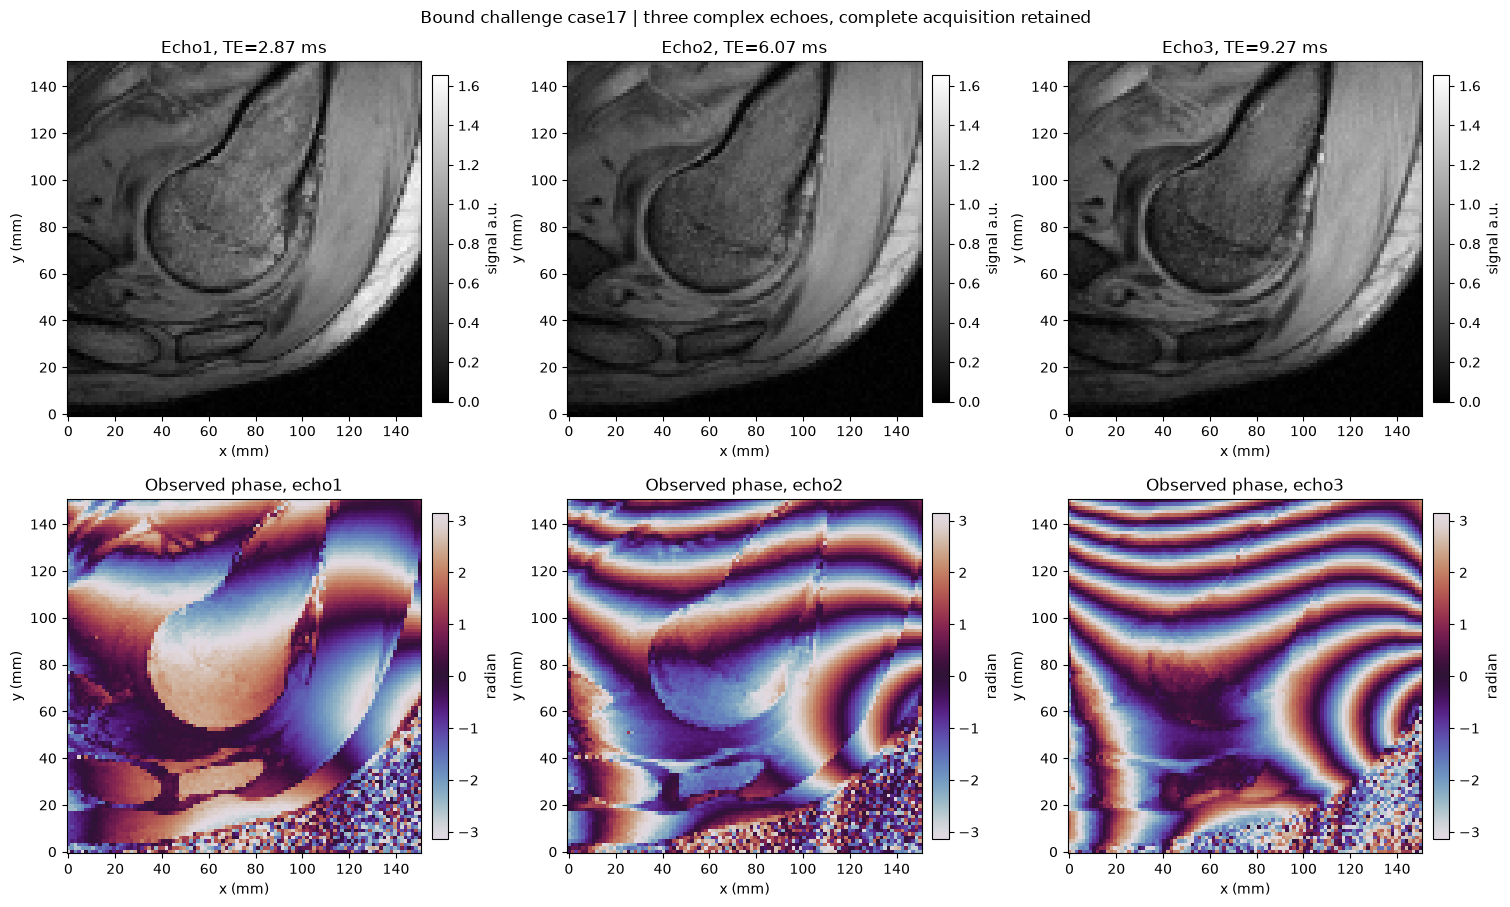

In [5]:
display(figures[0])
plt.close(figures[0])


### Fresh amplitudes, signal fraction, field and rate


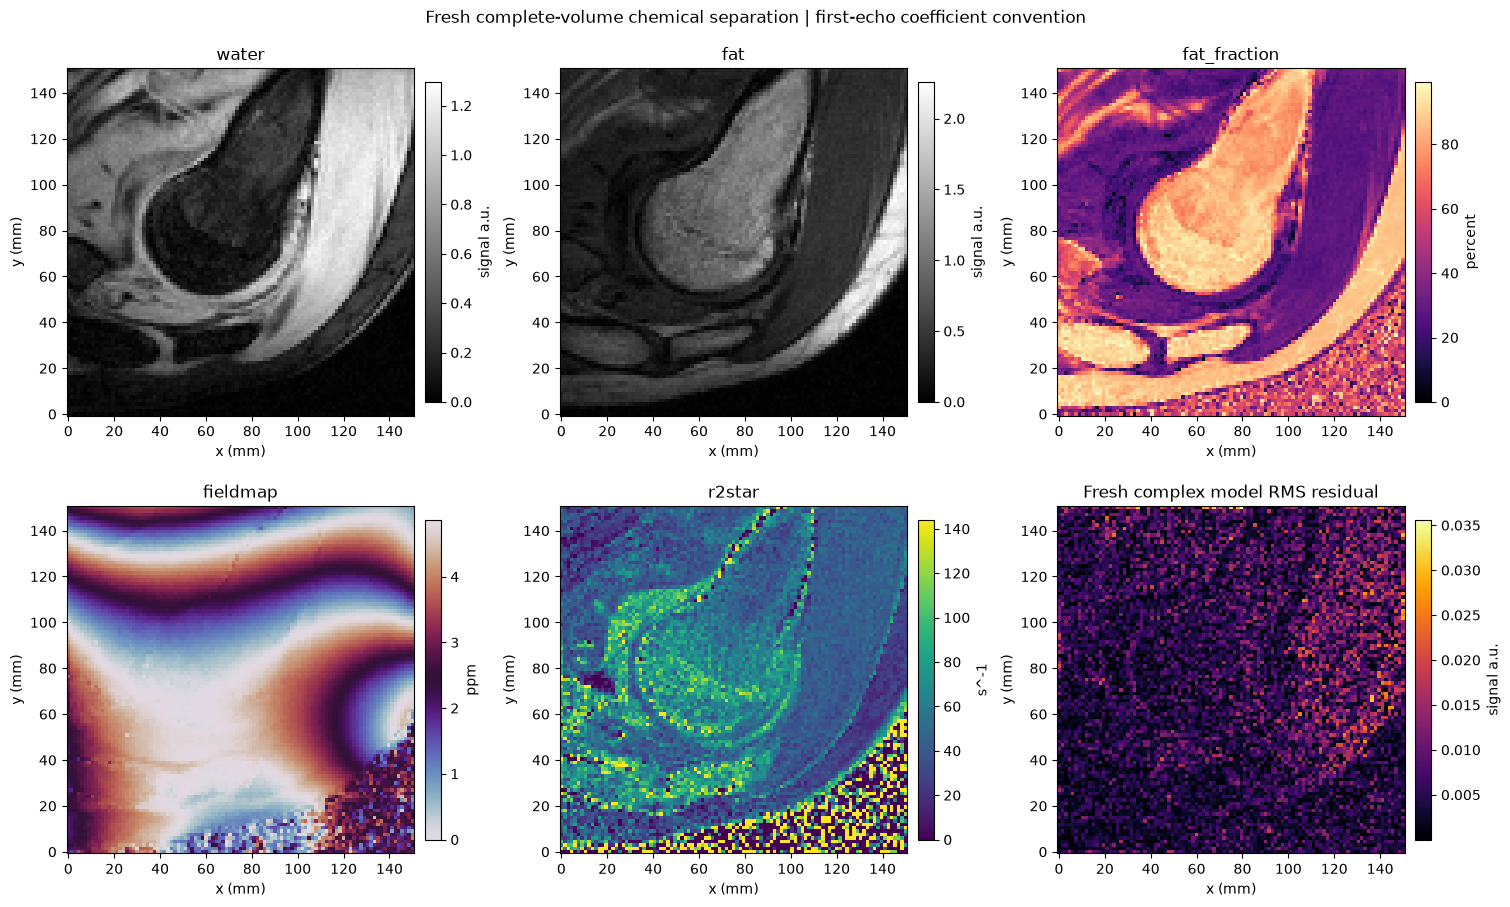

In [6]:
display(figures[1])
plt.close(figures[1])


### Same-data multiscale/conditional/regularization comparisons


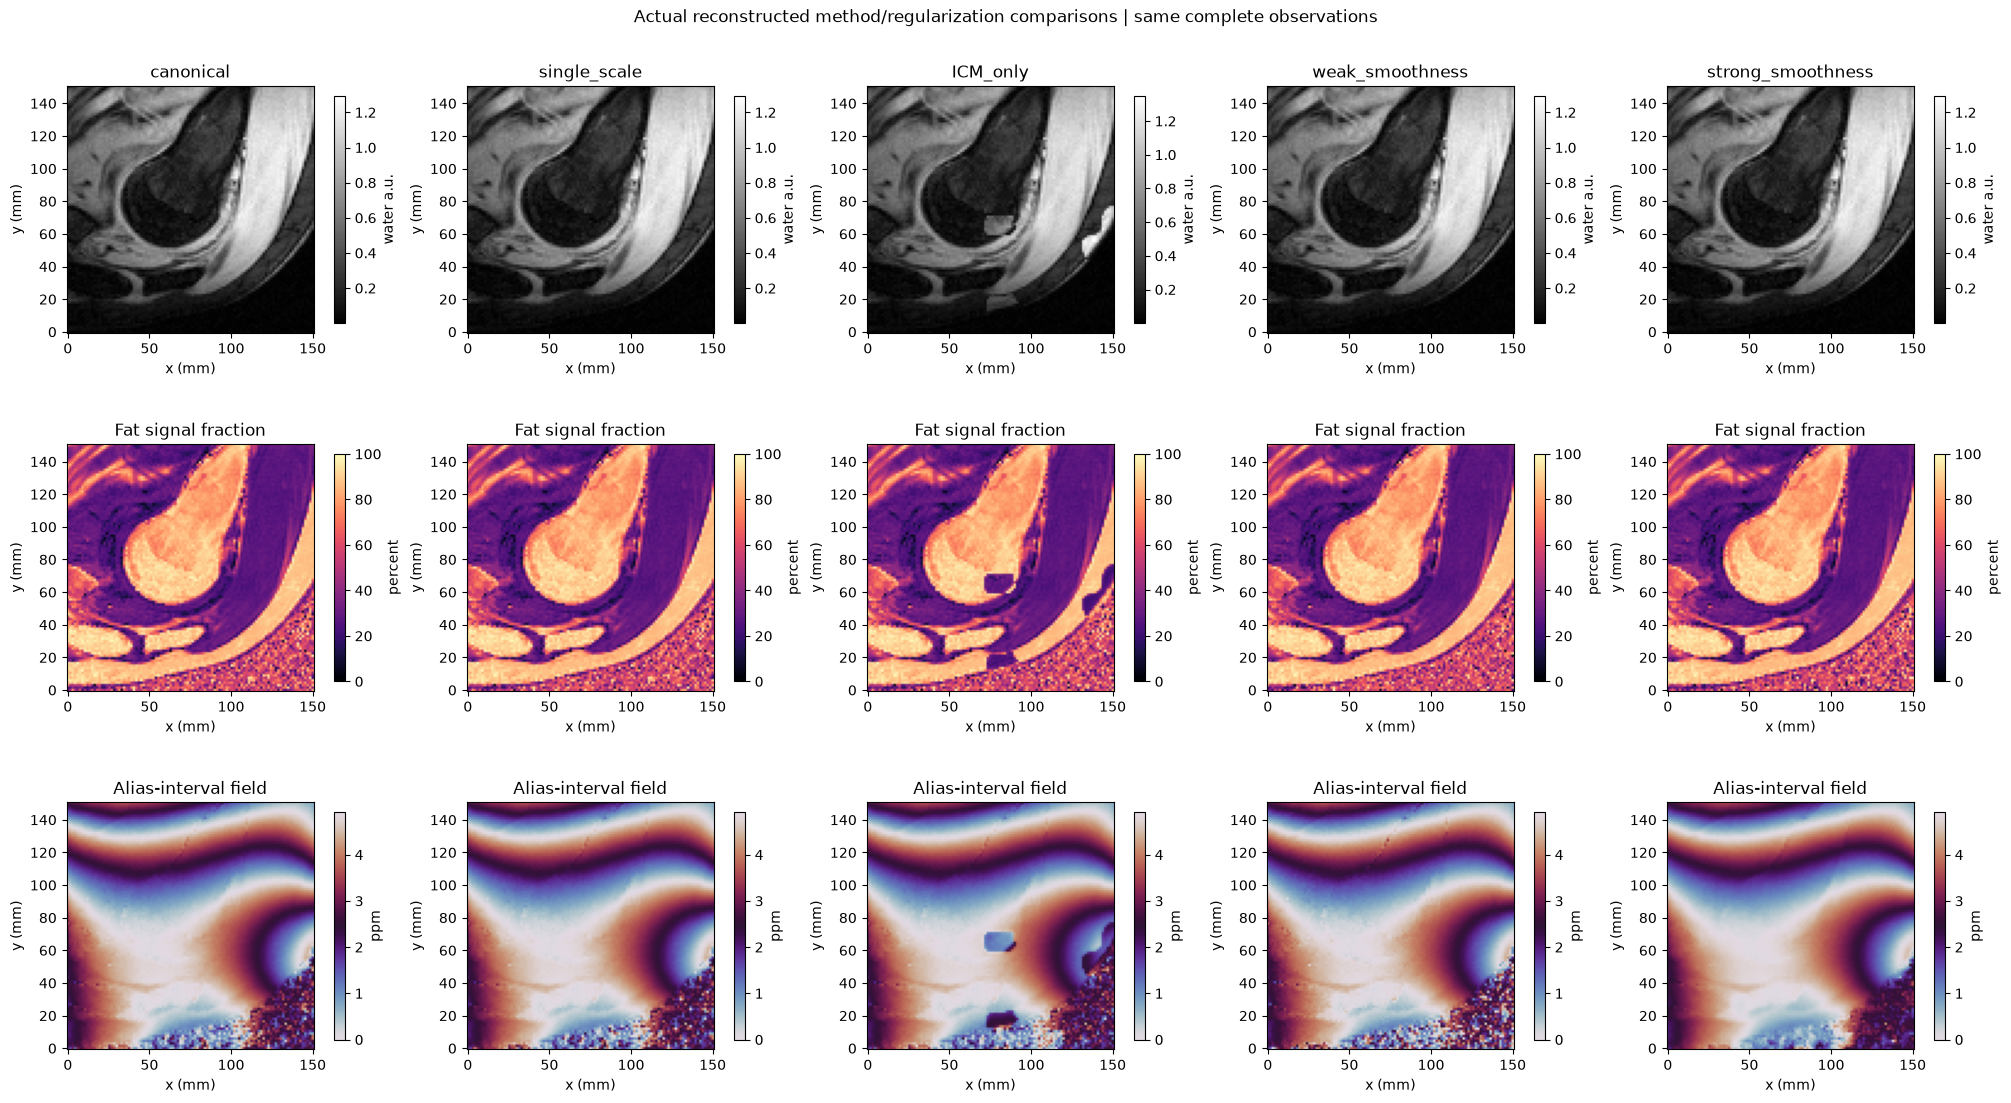

In [7]:
display(figures[2])
plt.close(figures[2])


### Single-scale versus multiscale under actually added noise


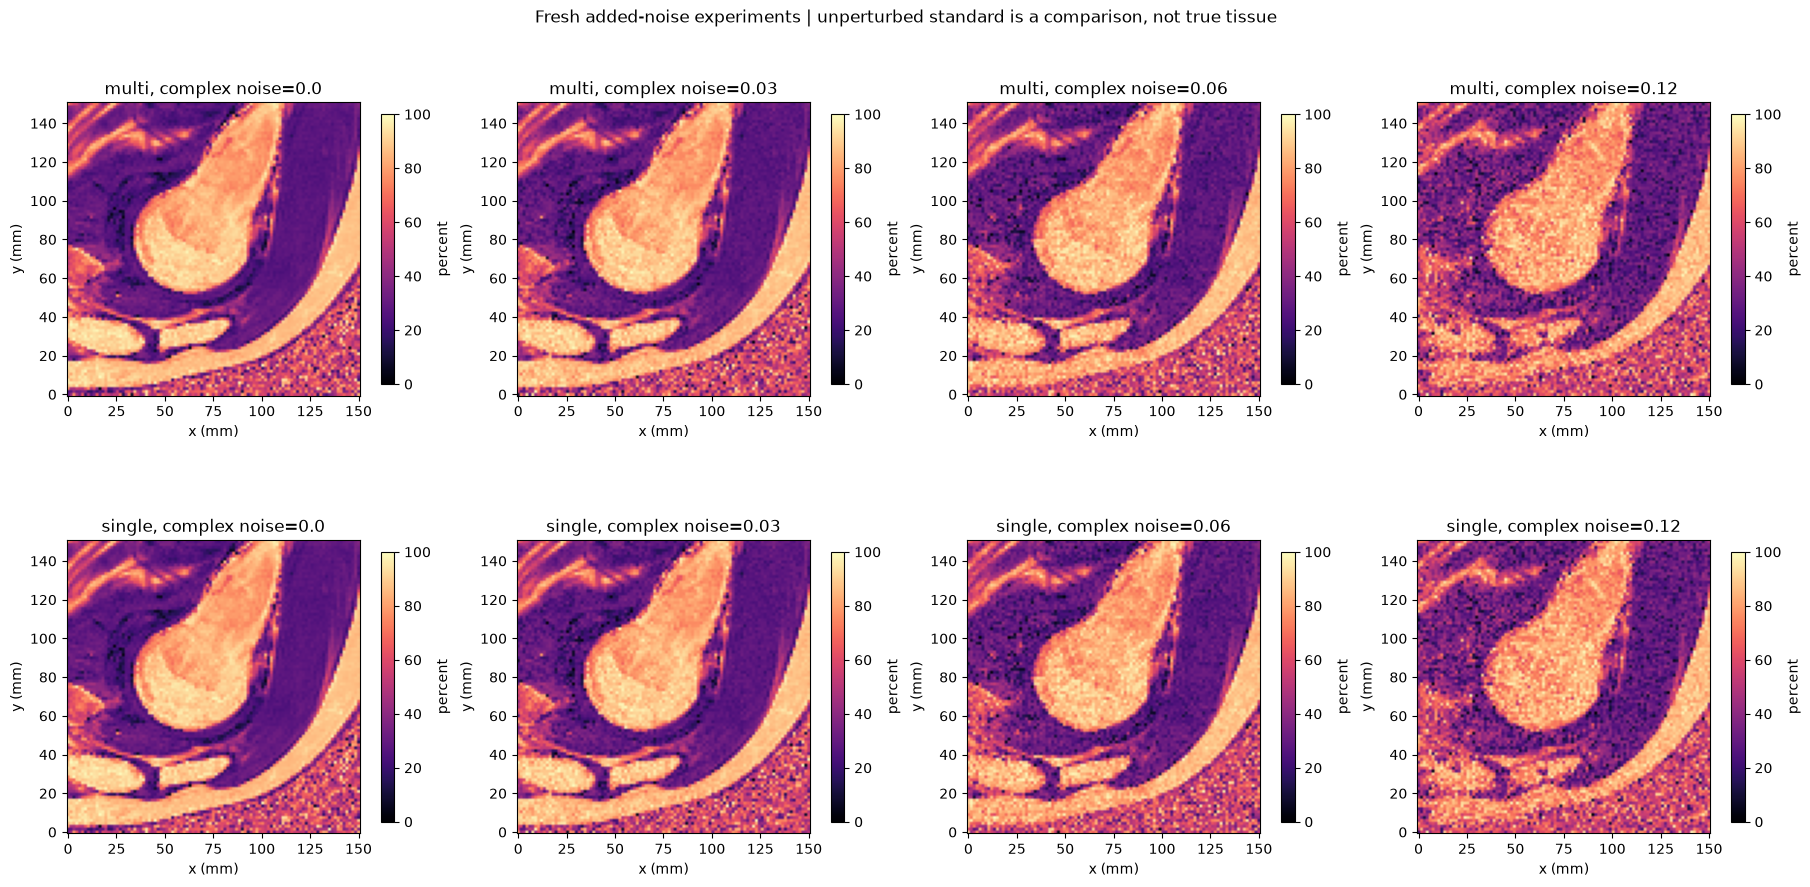

In [8]:
display(figures[3])
plt.close(figures[3])


### Complex model residual and observed ambiguity


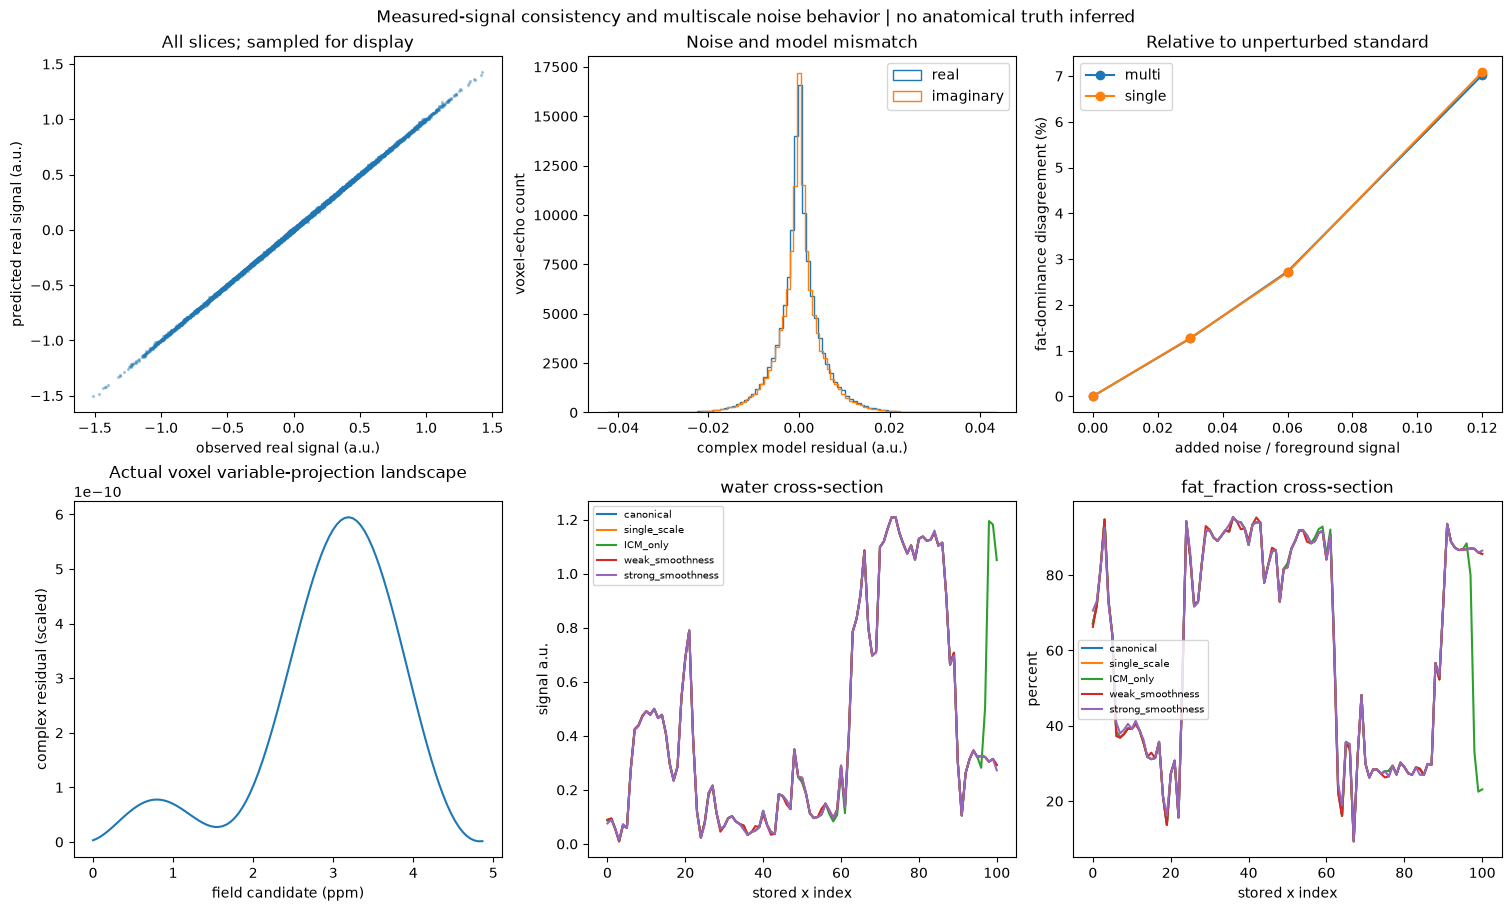

In [9]:
display(figures[4])
plt.close(figures[4])


### Qualified-source parity, complete volume and scientific limits


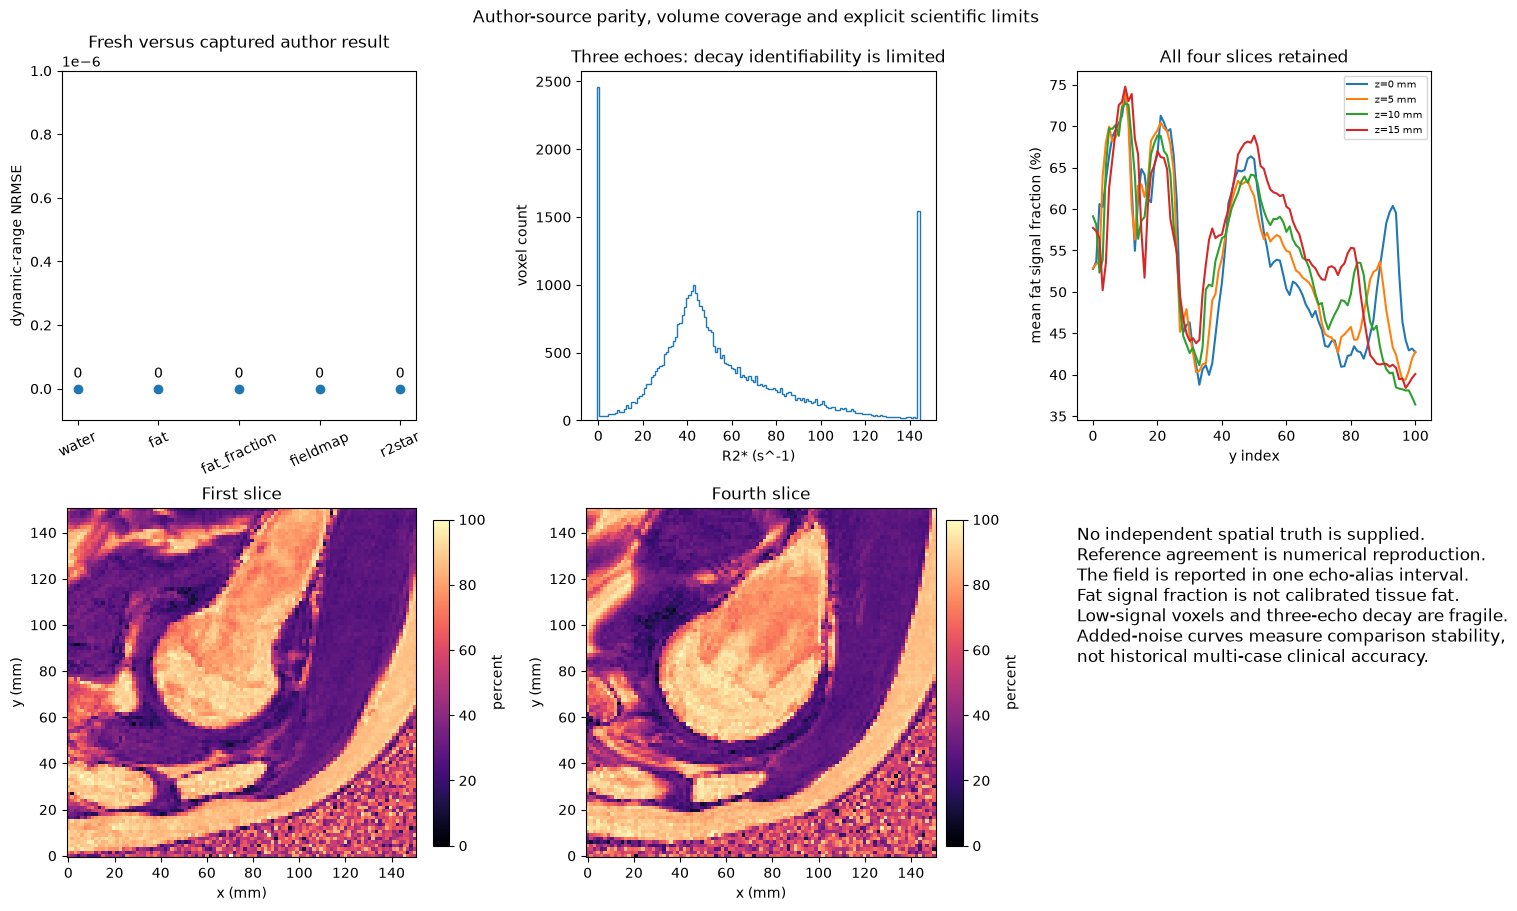

In [10]:
display(figures[5])
plt.close(figures[5])


### Independently justified endpoint correction and actual unmodified-source comparison


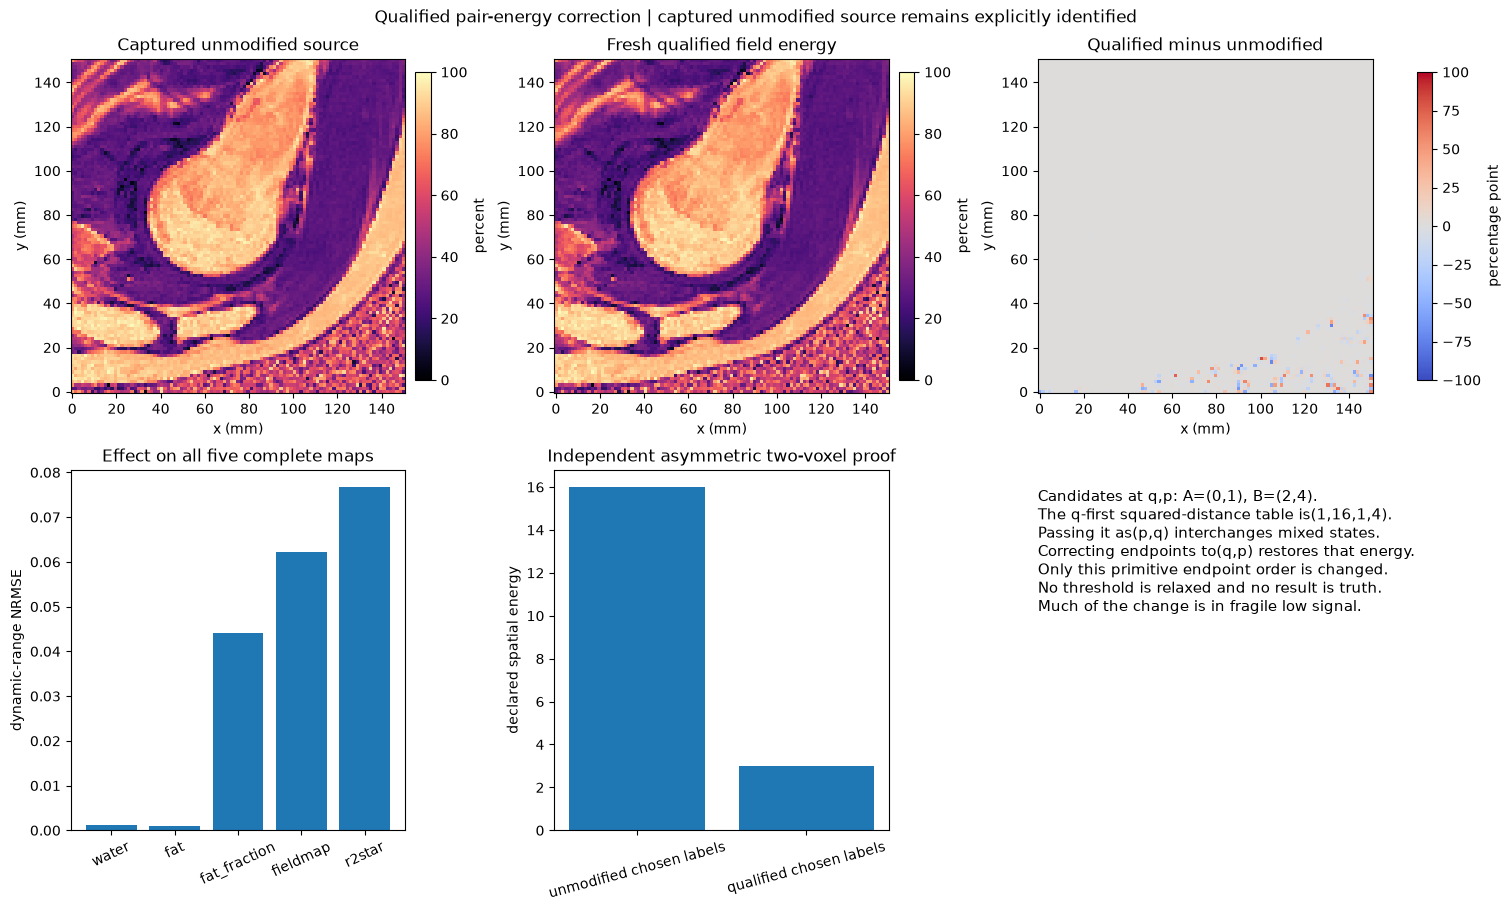

In [11]:
display(figures[6])
plt.close(figures[6])


## 6. Conclusion


The fresh local reconstruction agrees with the independently run author implementation on all five full-volume outputs and passes the standalone numerical-reproduction criterion. The scientific comparisons show how field coherence and multi-resolution information affect separation and perturbation stability on this example. They do not establish a uniquely correct field/decay/tissue composition: only three echoes are available, the field has an alias period, and no independent anatomical or quantitative fat truth was supplied. The signed complex convention, unnormalized fat spectrum, first-echo normalization and fixed field interval are essential to reproducibility.

Only three complex echoes constrain five reported maps plus internal phase conventions. Noise-added dominance disagreement is stability relative to the unperturbed estimator, not tissue error. The binary endpoint-order correction is qualified independently and must remain distinct from unchanged-source reproduction.
